# Seminar 1 · Part 2: The spam filter

**The story of today** (from the book *Probability and Statistics for Data Science*, section 4.8):

1. **Goal.** Estimate the conditional pmf of the class $\tilde{y}$ given the features $\tilde{x}$: $\;p_{\tilde{y}\mid\tilde{x}}(y \mid x)$. Then predict the most likely class, $\mathrm{MAP}(x) = \arg\max_y p_{\tilde{y}\mid\tilde{x}}(y \mid x)$.
2. **Attempt 1: just count.** $p_{\tilde{y}\mid\tilde{x}}(y \mid x) = p_{\tilde{x},\tilde{y}}(x, y) \,/\, p_{\tilde{x}}(x)$, and count the training examples equal to $x$. It fails: almost every new $x$ was never seen (the **curse of dimensionality**).
3. **Attempt 2: build the joint pmf from small pieces.** For messages, the naive assumption is made on the words: given the class and the length, the words are drawn independently, each from the same pmf $q_{y,1}, \dots, q_{y,\lvert V \rvert}$ on the vocabulary $V$. Then the counts have the **multinomial distribution**, and (with the length saying nothing about the class):
$$p_{\tilde{y}\mid\tilde{x}}(y \mid x) = \frac{p_{\tilde{y}}(y)\prod_{j=1}^{\lvert V \rvert} q_{y,j}^{\,x[j]}}{\sum_{k} p_{\tilde{y}}(k)\prod_{j=1}^{\lvert V \rvert} q_{k,j}^{\,x[j]}}$$
We only need to estimate the prior $p_{\tilde{y}}$ and the word probabilities $q_{y,j}$.

**scikit-learn** does all the counting and the computing for us. We read what it learned and check it against the slides.

Here: $x[j]$ is the number of times the $j$th word of the vocabulary $V$ appears in the message, and the class is ham or spam.

**How to use this notebook:** run the cells one by one from the top, with **Shift + Enter**. Read the text cells: they explain what each code cell does.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns                                    # nicer charts in one line

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.feature_extraction.text import CountVectorizer   # turns messages into word counts
from sklearn.naive_bayes import MultinomialNB                 # the naive Bayes classifier for word counts
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, accuracy_score
from sklearn.pipeline import make_pipeline

SEED = 0                                                 # fixed random seed: everyone gets the same split and the same numbers

## 1. Load the data

The SMS Spam Collection: one message per line, `label<TAB>text`.

In [2]:
data = pd.read_csv("../data/SMSSpamCollection", sep="\t", header=None,
                   names=["label", "text"], quoting=3)   # quoting=3: quote marks inside messages are ordinary characters
print("Messages:", len(data))
data.head()

Messages: 5574


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Some messages appear more than once. We keep one copy of each, so that a test message is never also a training message.

In [3]:
data = data.drop_duplicates(subset="text").reset_index(drop=True)
print("Messages left:", len(data))

data["spam"] = (data["label"] == "spam").astype(int)     # 1 = spam (the positive class), 0 = ham

Messages left: 5171


## 2. Look at the data

### How many ham and how many spam?

label
ham     4518
spam     653
Name: count, dtype: int64

ham is 87.4% of the messages


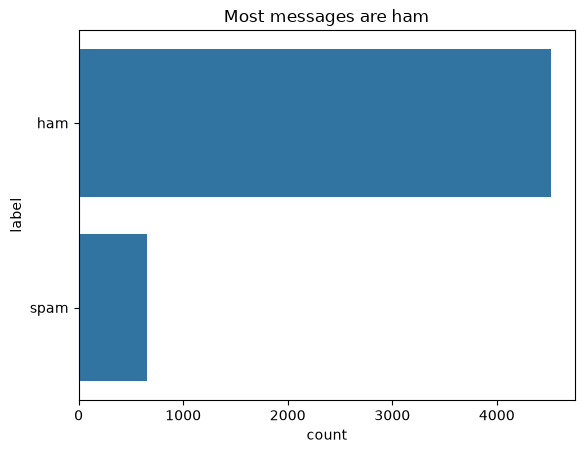

In [4]:
print(data["label"].value_counts())
print(f"\nham is {(data['label'] == 'ham').mean():.1%} of the messages")

sns.countplot(data=data, y="label")
plt.title("Most messages are ham")
plt.show()

### Some messages

In [5]:
for label in ["spam", "ham"]:
    print(label.upper() + ":")
    for t in data[data["label"] == label]["text"].head(3):
        print("  -", t)

SPAM:
  - Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
  - FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
  - WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
HAM:
  - Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  - Ok lar... Joking wif u oni...
  - U dun say so early hor... U c already then say...


### Words

A **word** is a run of letters and digits, after the message is turned into lower case. `CountVectorizer` cuts a message into words with this rule:

In [6]:
words = CountVectorizer(token_pattern=r"[a-z0-9]+").build_analyzer()   # a function: message -> list of words
print(words("Free entry in 2 a wkly comp to win FA Cup final tkts!"))

['free', 'entry', 'in', '2', 'a', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts']


### Spam messages are longer

$s$ = the length of a message: its number of words, counting repeats.

label
ham     11.0
spam    27.0
Name: s, dtype: float64


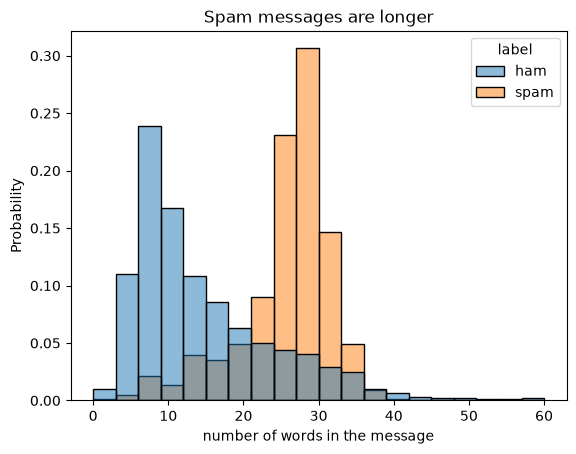

In [7]:
data["s"] = data["text"].apply(lambda t: len(words(t)))
print(data.groupby("label")["s"].median())

sns.histplot(data=data, x="s", hue="label", stat="probability", common_norm=False, binwidth=3, binrange=(0, 60))
plt.xlabel("number of words in the message")
plt.title("Spam messages are longer")
plt.show()

## 3. Training set and test set

80% of the messages to learn from, 20% kept apart to test the classifier at the end.

In [8]:
train, test = train_test_split(data, test_size=0.2, random_state=SEED)
print("Training set:", len(train), "messages")
print("Test set:    ", len(test), "messages")

Training set: 4136 messages
Test set:     1035 messages


## 4. Attempt 1: just count

$p_{\tilde{y}\mid\tilde{x}}(y \mid x) \approx$ (training messages with counts $x$ and class $y$) / (training messages with counts $x$).

How many test messages can we classify this way? Only those whose counts $x$ also appear in the training set:

In [9]:
vocabulary = set(CountVectorizer(token_pattern=r"[a-z0-9]+").fit(train["text"]).vocabulary_)   # V: the words of the training messages

def bag(text):
    """The words of the message that are in V, sorted.
    Sorting forgets the order, so two messages have the same bag exactly when they have the same counts x."""
    return tuple(sorted(w for w in words(text) if w in vocabulary))

train_bags = set(train["text"].apply(bag))
seen = test["text"].apply(lambda t: bag(t) in train_bags)   # True if the counts of this test message appear in training
print("Test messages whose counts appear in the training set:", seen.sum(), "of", len(test))

Test messages whose counts appear in the training set: 15 of 1035


Only 15 of 1,035. For the other 1,020, counting gives $0/0$. And there are far too many possible messages to ever see them all:

In [10]:
V = len(CountVectorizer(token_pattern=r"[a-z0-9]+").fit(train["text"]).vocabulary_)   # the number of different words
print("Words in the training messages:", V)
print(f"Possible messages of 10 words: {V}^10 = {V**10:.1e}")

Words in the training messages: 7666
Possible messages of 10 words: 7666^10 = 7.0e+38


## 5. Attempt 2: naive Bayes, on the 12 toy messages of the slides

`CountVectorizer` gives the counts $x[j]$ of every word of $V$ in every message: one row per message (its vector $x$), one column per word.

In [11]:
toy_texts = ["lunch meeting", "meeting lunch", "free lunch", "lunch money",
             "meeting", "meeting money", "lunch", "meeting lunch meeting",       # 8 ham
             "free money", "win money", "win free free", "free win money money"]  # 4 spam
toy_labels = ["ham"] * 8 + ["spam"] * 4

toy_vectorizer = CountVectorizer(token_pattern=r"[a-z0-9]+")
X_toy = toy_vectorizer.fit_transform(toy_texts)
pd.DataFrame(X_toy.toarray(), columns=toy_vectorizer.get_feature_names_out(), index=toy_texts)

,free,lunch,meeting,money,win
lunch meeting,0,1,1,0,0
meeting lunch,0,1,1,0,0
free lunch,1,1,0,0,0
lunch money,0,1,0,1,0
meeting,0,0,1,0,0
meeting money,0,0,1,1,0
lunch,0,1,0,0,0
meeting lunch meeting,0,1,2,0,0
free money,1,0,0,1,0
win money,0,0,0,1,1


`MultinomialNB` estimates the prior $p_{\tilde{y}}$ and the word probabilities $q_{y,j}$ by counting, with Laplace smoothing (`alpha=1`: add 1 to every count). `predict_proba` gives the posterior $p_{\tilde{y}\mid\tilde{x}}(y \mid x)$ of each class.

In [12]:
toy_model = MultinomialNB(alpha=1)
toy_model.fit(X_toy, toy_labels)

new = ["free money", "free win money meeting"]
pd.DataFrame(toy_model.predict_proba(toy_vectorizer.transform(new)), index=new, columns=toy_model.classes_).round(2)

,ham,spam
free money,0.24,0.76
free win money meeting,0.26,0.74


"free win money meeting": 0.74 spam, as on the slide "The fix: Laplace smoothing". ("free money": 0.77 here; 0.88 on the slide, which is without smoothing.)

## 6. Train it on the real messages

In [13]:
vectorizer = CountVectorizer(token_pattern=r"[a-z0-9]+")
X_train = vectorizer.fit_transform(train["text"])        # word counts of the training messages; learns the vocabulary V
X_test = vectorizer.transform(test["text"])              # word counts of the test messages (unknown words are dropped)

model = MultinomialNB(alpha=1)
model.fit(X_train, train["spam"])

print("Vocabulary size |V|:", len(vectorizer.vocabulary_))

Vocabulary size |V|: 7666


### What is inside the trained model?

`fit` only counts. The model keeps the counts, and the estimates made from them, as **attributes**: names that end with `_`.

Here $n$ is the number of training messages, and feature $j$ is the $j$th word of $V$ (column $j$ of `X_train`).

| Attribute | Shape | What it is |
|---|---|---|
| `classes_` | 2 | The class values $y$: 0 = ham, 1 = spam. Row 0 of the arrays below is ham, row 1 is spam. |
| `class_count_` | 2 | $n_y$: the number of training messages of class $y$. |
| `class_log_prior_` | 2 | $\log p_{\tilde{y}}(y)$, where $p_{\tilde{y}}(y) = n_y / n$. |
| `feature_count_` | 2 × $\lvert V \rvert$ | $\text{count}(j, y)$: how often the $j$th word of $V$ appears in the training messages of class $y$. |
| `feature_log_prob_` | 2 × $\lvert V \rvert$ | $\log q_{y,j}$, with Laplace smoothing (`alpha=1`): $\;q_{y,j} = \dfrac{\text{count}(j, y) + 1}{\sum_{j'=1}^{\lvert V \rvert} \text{count}(j', y) + \lvert V \rvert}$ |
| `n_features_in_` | number | $\lvert V \rvert$, the number of columns of `X_train`. |

- The probabilities are stored as **logs**. `np.exp` gives them back.
- **Careful:** the scikit-learn documentation writes `feature_log_prob_` as $P(x_i \mid y)$. In our notation it is $\log q_{y,j}$: the probability that **one word** of a class-$y$ message is the $j$th word of $V$. It is not the pmf of the count $x[j]$.
- The attribute `feature_names_in_` is **not set here**, because `X_train` has no column names. The words are in `vectorizer.get_feature_names_out()`, in the order of the columns.

In [14]:
print("classes_:      ", model.classes_, "         (0 = ham, 1 = spam)")
print("class_count_:  ", model.class_count_, "   (n_ham, n_spam)")
print("exp(class_log_prior_):", np.exp(model.class_log_prior_).round(3), "  (p(ham), p(spam))")
print("n_features_in_:", model.n_features_in_, "              (|V|)")
print("feature_count_ shape:   ", model.feature_count_.shape)       # (2 classes, |V| words)
print("feature_log_prob_ shape:", model.feature_log_prob_.shape)

classes_:       [0 1]          (0 = ham, 1 = spam)
class_count_:   [3618.  518.]    (n_ham, n_spam)
exp(class_log_prior_): [0.875 0.125]   (p(ham), p(spam))
n_features_in_: 7666               (|V|)
feature_count_ shape:    (2, 7666)
feature_log_prob_ shape: (2, 7666)


The two big arrays, for the 5 words of the toy example: $\text{count}(j, y)$ and $q_{y,j}$.

In [15]:
vocab_words = list(vectorizer.get_feature_names_out())    # the words of V, in the order of the columns
toy_words = ["free", "lunch", "meeting", "money", "win"]
cols = [vocab_words.index(w) for w in toy_words]          # the column j of each word
q = np.exp(model.feature_log_prob_)                       # q[y, j] = q_{y,j}

pd.DataFrame({
    "count(j, ham)":  model.feature_count_[0, cols].astype(int),
    "count(j, spam)": model.feature_count_[1, cols].astype(int),
    "q_ham,j":        q[0, cols].round(5),
    "q_spam,j":       q[1, cols].round(5),
}, index=toy_words)

,"count(j, ham)","count(j, spam)","q_ham,j","q_spam,j"
free,49,152,0.00082,0.00736
lunch,30,0,0.00051,0.00005
meeting,31,0,0.00052,0.00005
money,47,1,0.00078,0.00010
win,6,36,0.00011,0.00178


"lunch" and "meeting" never appear in a spam training message: the count is 0, but $q_{\text{spam},j} > 0$. That is Laplace smoothing at work.

### Check: training = counting

We count by ourselves, from `X_train`, and compare with what the model stored.

In [16]:
y_train = train["spam"].to_numpy()                       # the labels y_i: 0 = ham, 1 = spam
n = len(y_train)                                         # number of training messages
n_y = np.array([(y_train == 0).sum(), (y_train == 1).sum()])                # n_ham, n_spam
count = np.asarray(np.vstack([X_train[y_train == 0].sum(axis=0),             # count(j, ham), for every word j
                              X_train[y_train == 1].sum(axis=0)]))           # count(j, spam)
q_ours = (count + 1) / (count.sum(axis=1, keepdims=True) + X_train.shape[1])  # Laplace smoothing; X_train.shape[1] = |V|

print("prior  n_y / n  :", np.allclose(n_y / n, np.exp(model.class_log_prior_)))
print("count(j, y)     :", np.allclose(count, model.feature_count_))
print("q_{y,j}         :", np.allclose(q_ours, np.exp(model.feature_log_prob_)))

prior  n_y / n  : True
count(j, y)     : True
q_{y,j}         : True


### What did it learn?

For each word $j$ of $V$: how much more likely it is in spam than in ham, $\log q_{\text{spam},j} - \log q_{\text{ham},j}$. We look only at words that appear at least 10 times.

In [17]:
table = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "count": np.asarray(X_train.sum(axis=0)).ravel(),                          # how often the word appears in training
    "spamminess": model.feature_log_prob_[1] - model.feature_log_prob_[0],    # log q_spam,j - log q_ham,j
})
common = table[table["count"] >= 10].sort_values("spamminess")
print("Most spammy:", list(common["word"].tail(12)[::-1]))
print("Most hammy: ", list(common["word"].head(12)))

Most spammy: ['claim', 'prize', '150p', 'tone', 'guaranteed', 'co', '18', 'www', 'cs', '500', '1000', 'awarded']
Most hammy:  ['gt', 'lt', 'he', 'lor', 'da', 'she', 'k', 'too', 'later', 'say', 'ask', 'already']


## 7. Use it

Write your own messages:

In [18]:
my_messages = [
    "Congratulations! You have won a FREE prize. Call now to claim",
    "are we still meeting for lunch tomorrow?",
    "URGENT your mobile number has been selected, reply WIN",
    "sorry i will be late, see you at home",
]
p_spam = model.predict_proba(vectorizer.transform(my_messages))[:, 1]       # column 1 = the class spam
pd.DataFrame({"message": my_messages, "p(spam | x)": p_spam.round(3)})

,message,p(spam | x)
0,Congratulations! You have won a FREE prize. Ca...,1.0
1,are we still meeting for lunch tomorrow?,0.0
2,"URGENT your mobile number has been selected, r...",1.0
3,"sorry i will be late, see you at home",0.0


## 8. Evaluate it on the test set

The confusion matrix. Careful: scikit-learn puts the **true** class in the rows and the **predicted** class in the columns (the slides do the opposite).

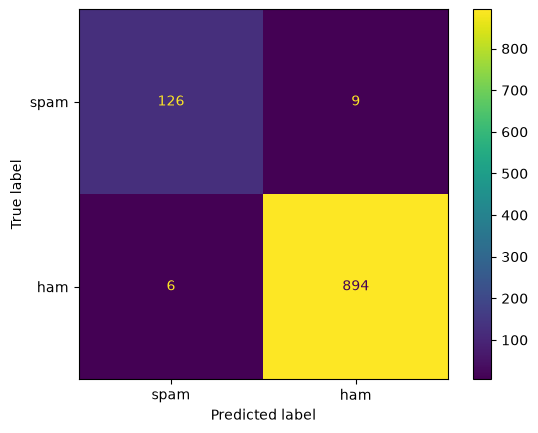

precision = 0.955
recall    = 0.933
accuracy  = 0.986


In [19]:
predicted = model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(test["spam"], predicted, labels=[1, 0], display_labels=["spam", "ham"])
plt.show()

print(f"precision = {precision_score(test['spam'], predicted):.3f}")
print(f"recall    = {recall_score(test['spam'], predicted):.3f}")
print(f"accuracy  = {accuracy_score(test['spam'], predicted):.3f}")

The lazy filter "always ham": high accuracy, but it catches no spam at all.

In [20]:
always_ham = np.zeros(len(test), dtype=int)
print(f"'always ham': accuracy = {accuracy_score(test['spam'], always_ham):.3f}, recall = {recall_score(test['spam'], always_ham):.3f}")

'always ham': accuracy = 0.870, recall = 0.000


### The mistakes

In [21]:
test_result = test.assign(predicted=predicted)
print("Spam that got through (false negatives):")
for t in test_result.query("spam == 1 and predicted == 0")["text"].head(5):
    print("  -", t)
print("\nHam sent to the spam folder (false positives):")
for t in test_result.query("spam == 0 and predicted == 1")["text"].head(5):
    print("  -", t)

Spam that got through (false negatives):
  - CALL 09090900040 & LISTEN TO EXTREME DIRTY LIVE CHAT GOING ON IN THE OFFICE RIGHT NOW TOTAL PRIVACY NO ONE KNOWS YOUR [sic] LISTENING 60P MIN 24/7MP 0870753331018+
  - For sale - arsenal dartboard. Good condition but no doubles or trebles!
  - You can donate £2.50 to UNICEF's Asian Tsunami disaster support fund by texting DONATE to 864233. £2.50 will be added to your next bill
  - Hi babe its Chloe, how r u? I was smashed on saturday night, it was great! How was your weekend? U been missing me? SP visionsms.com Text stop to stop 150p/text
  - SMS. ac sun0819 posts HELLO:"You seem cool, wanted to say hi. HI!!!" Stop? Send STOP to 62468

Ham sent to the spam folder (false positives):
  - Have you laid your airtel line to rest?
  - We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us
  - Waiting for your call.
  - Unlimited texts. Limited minutes.
  - No calls..messages..missed calls


### 10-fold cross-validation (on the training set)

`make_pipeline` glues the two steps together (count the words, then naive Bayes), so that each fold learns its own vocabulary.

In [22]:
pipeline = make_pipeline(CountVectorizer(token_pattern=r"[a-z0-9]+"), MultinomialNB(alpha=1))
cv = cross_validate(pipeline, train["text"], train["spam"], cv=10, scoring=["precision", "recall", "accuracy"])
pd.DataFrame(cv)[["test_precision", "test_recall", "test_accuracy"]].mean().round(3)

test_precision    0.986
test_recall       0.907
test_accuracy     0.987
dtype: float64

## 9. Can you fool the model?

Take a spam message that the filter catches, and add "hammy" words to it, one by one.

In [23]:
spam_message = test_result.query("spam == 1 and predicted == 1")["text"].iloc[0]
print("Original:", spam_message)

message = spam_message
for w in [w for w in common["word"] if w not in ("gt", "lt")][:8]:      # the 8 most hammy words ("gt", "lt" are HTML leftovers)
    message = message + " " + w
    p = model.predict_proba(vectorizer.transform([message]))[0, 1]
    print(f"+ {w:8}  p(spam | x) = {p:.4f}")

Original: XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobilemovieclub.com?n=QJKGIGHJJGCBL
+ he        p(spam | x) = 1.0000
+ lor       p(spam | x) = 0.9985
+ da        p(spam | x) = 0.9442
+ she       p(spam | x) = 0.3027
+ k         p(spam | x) = 0.0113
+ too       p(spam | x) = 0.0004
+ later     p(spam | x) = 0.0000
+ say       p(spam | x) = 0.0000


Your turn: write a spam message that the filter calls ham.

In [24]:
my_attack = "WIN a FREE holiday! Text YES to 80082"
print(f"p(spam | x) = {model.predict_proba(vectorizer.transform([my_attack]))[0, 1]:.3f}")

p(spam | x) = 1.000


## Summary

- Counting whole messages fails: every test message is new (the curse of dimensionality).
- Naive Bayes builds the joint pmf from small pieces: the prior and one pmf of words per class. Training = counting.
- `CountVectorizer` + `MultinomialNB`: a spam filter in a few lines.

**Read more:** Fernandez-Granda, *Probability and Statistics for Data Science*, sections 4.7–4.8. Jurafsky & Martin, Appendix B, sections B.1–B.3 and B.7–B.8.